## Assignment 2

In [1]:
import json
import numpy as np
import matplotlib.pyplot as plt
from numba import njit

from scipy.sparse import diags
from scipy.sparse.linalg import eigsh

In [2]:
tsn = "200101723"
d = int(tsn[-3:])
ALPHA = 0.3 + d / 5000
print(f"alpha = {ALPHA}")

M = 1
HBAR = 1
OMEGA = 2 * np.sqrt(2)

BOXSIZE = 8
ND = 600
DX = BOXSIZE / ND
DT = np.pi / 128
XMIN = 1 / np.sqrt(ALPHA)
x = np.linspace(-BOXSIZE / 2, BOXSIZE / 2, ND + 1)
print(f"Positions: {x.size}, Spacing: {DX:.4f}")

@njit
def V(x, alpha):
	return alpha * x**4 - 2 * x**2 + 1 / alpha
print(f"Potential - V(0) = {V(0, ALPHA):.4f}, V(+XMIN) = {V(XMIN, ALPHA):.4f}," + 
      f" V(-XMIN) = {V(-XMIN, ALPHA):.4f}")

def V_plus(x):
	return 4 * (x - XMIN)**2

def V_minus(x):
	return 4 * (x + XMIN)**2

def psi_harmonic(x, xmin):
    return (OMEGA / np.pi)**0.25 * np.exp(-OMEGA / 2 * (x - xmin)**2)

psi_plus = psi_harmonic(x, XMIN)
psi_minus = psi_harmonic(x, -XMIN)

psi_S = (psi_plus + psi_minus) / np.sqrt(2)
psi_A = (psi_plus - psi_minus) / np.sqrt(2)

alpha = 0.4446
Positions: 601, Spacing: 0.0133
Potential - V(0) = 2.2492, V(+XMIN) = 0.0000, V(-XMIN) = 0.0000


### Problem A

In [3]:
@njit
def func_K(x_a, x_b, dt, alpha):
    kinetic = 0.5 * (x_b - x_a)**2 / dt
    potential = V((x_a + x_b) / 2, alpha) * dt
    return np.exp(1j * (kinetic - potential))

@njit
def build_kernel(x, dt, alpha):
    kernel = np.empty((x.size, x.size), dtype=np.complex128)
    for i in range(x.size):
        for j in range(x.size):
            kernel[i, j] = func_K(x[j], x[i], dt, alpha)
    return kernel

K_dt = build_kernel(x, DT, ALPHA)
print("Kernel shape:", K_dt.shape)

@njit
def step(psi, kernel, dx):
    psi_next = dx * (kernel @ psi)
    norm = np.sqrt(dx * np.sum(np.abs(psi_next)**2))
    return psi_next / norm
    
@njit
def evolve(psi_initial, kernel, dx, nt):
    psi = np.empty((nt + 1, psi_initial.size), dtype=np.complex128)
    psi[0] = psi_initial

    for n in range(nt):
        psi[n + 1] = step(psi[n], kernel, dx)

    return psi

T = 2 * np.pi / 0.16284330
NT = int(np.ceil(T / DT))
t = np.arange(NT + 1) * DT

psi_initial = psi_plus.astype(np.complex128)
psi_initial /= np.sqrt(DX * np.sum(np.abs(psi_initial)**2))
psi = evolve(psi_initial, K_dt, DX, NT)

prob = np.abs(psi)**2
x_mean = DX * (prob @ x)

Kernel shape: (601, 601)


In [4]:
mask = (t >= 10) & (t <= 28)
indices = np.where(mask)[0]
min_index = indices[np.argmin(x_mean[indices])]

t_tunnel = t[min_index]
x_tunnel = x_mean[min_index]

print(f"Tunneling time: {t_tunnel:.4f}")
print(f"Mean position: {x_tunnel:.4f}")

Tunneling time: 17.7942
Mean position: -1.3836


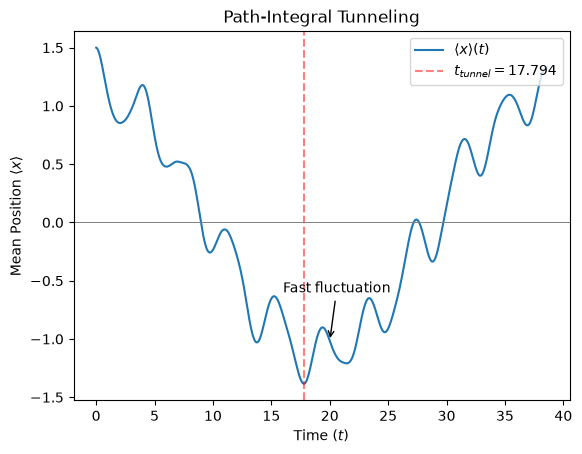

In [5]:
fig, ax = plt.subplots()
plt.plot(t, x_mean, label=r"$\langle x \rangle(t)$")
plt.axvline(t_tunnel, color="red", linestyle="--", alpha=0.5,
            label=fr"$t_{{tunnel}} = {t_tunnel:.3f}$")
plt.axhline(0, color="gray", linewidth=0.7)
ax.annotate(
    "Fast fluctuation",
    xy=(20, x_mean[np.argmin(np.abs(t - 20))]),
    xytext=(16, -0.6),
    arrowprops=dict(arrowstyle="->"),
)

ax.set(xlabel="Time $(t)$", ylabel=r"Mean Position $\langle x \rangle$",
       title="Path-Integral Tunneling")
plt.legend(loc="upper right")
plt.show()

### Problem B

In [7]:
def build_hamiltonian(x, dx, alpha):
    n = x.size

    main_diag = 1 / dx**2 + V(x, alpha)
    off_diag = np.full(n - 1, -1 / (2 * dx**2))

    H = diags(
        [off_diag, main_diag, off_diag],
        offsets=[-1, 0, 1],
        format="csr"
    )

    return H

def solve_eigenstates(x, dx, alpha):
    H = build_hamiltonian(x, dx, alpha)

    energies, states = eigsh(H, k=2, sigma=0, which="LM")

    order = np.argsort(energies)
    energies = energies[order]
    states = states[:, order]

    for i in range(2):
        states[:, i] /= np.sqrt(dx * np.sum(np.abs(states[:, i])**2))

    if states[np.argmax(np.abs(states[:, 0])), 0] < 0:
        states[:, 0] *= -1

    if states[np.argmin(np.abs(x - 1 / np.sqrt(alpha))), 1] < 0:
        states[:, 1] *= -1

    return energies, states

for alpha_test in [0.4, 0.6]:
    energies, _ = solve_eigenstates(x, DX, alpha_test)

    print(f"alpha = {alpha_test}, lambda = {alpha_test / 4}")
    print(f"E0 = {energies[0]:.8f}")
    print(f"E1 = {energies[1]:.8f}")

alpha = 0.4, lambda = 0.1
E0 = 1.23447724
E1 = 1.34690427
alpha = 0.6, lambda = 0.15
E0 = 1.06247981
E1 = 1.42104358


In [19]:
energies, states = solve_eigenstates(x, DX, ALPHA)

E0, E1 = energies
phi0 = states[:, 0]
phi1 = states[:, 1]

delta_E = E1 - E0

print(f"E0 = {E0:.8f}")
print(f"E1 = {E1:.8f}")
print(f"Delta E = {delta_E:.8f}")

grids = [
    ("Original", 4, 600),
    ("Half spacing", 4, 1200),
    ("Larger box", 6, 900)
]

convergence_results = []

for name, half_box, nd in grids:
    x_test = np.linspace(-half_box, half_box, nd + 1)
    dx_test = 2 * half_box / nd

    energies_test, _ = solve_eigenstates(x_test, dx_test, ALPHA)

    E0_test, E1_test = energies_test
    gap_test = E1_test - E0_test

    convergence_results.append((name, E0_test, E1_test, gap_test))

original_gap = convergence_results[0][3]

print(f"{'Grid':<16} {'E0':>12} {'E1':>12} {'Gap':>12} {'Gap change':>14}")

for name, e0, e1, gap in convergence_results:
    print(f"{name:<16} {e0:12.8f} {e1:12.8f} "
          f"{gap:12.8f} {gap - original_gap:+14.8f}")

E0 = 1.19457165
E1 = 1.35741495
Delta E = 0.16284330
Grid                       E0           E1          Gap     Gap change
Original           1.19457165   1.35741495   0.16284330    +0.00000000
Half spacing       1.19459193   1.35744304   0.16285111    +0.00000781
Larger box         1.19457165   1.35741495   0.16284330    -0.00000000


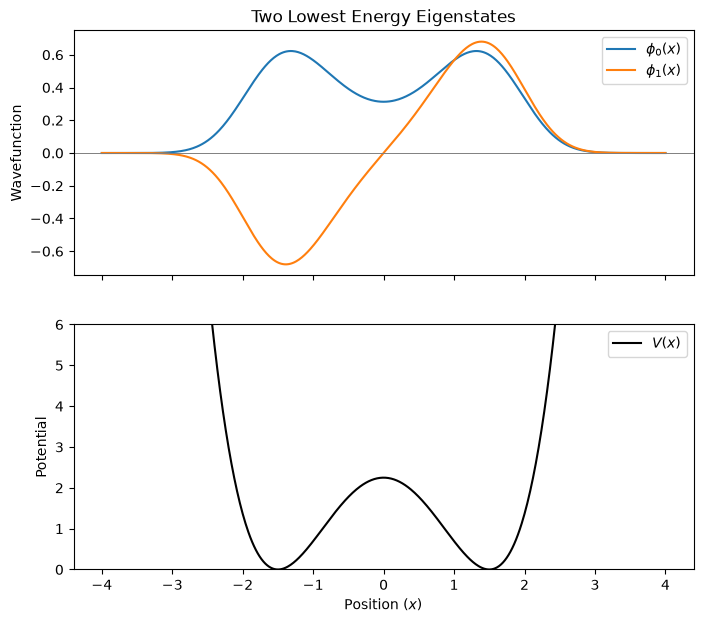

In [29]:
fig, (ax1, ax2) = plt.subplots(
    2, 1, figsize=(8, 7), sharex=True
)

ax1.plot(x, phi0, label=r"$\phi_0(x)$")
ax1.plot(x, phi1, label=r"$\phi_1(x)$")
ax1.axhline(0, color="gray", linewidth=0.7)
ax1.set(ylabel="Wavefunction",
        title="Two Lowest Energy Eigenstates")
ax1.legend()

ax2.plot(x, V(x, ALPHA), color="black", label=r"$V(x)$")
ax2.set(xlabel="Position $(x)$", ylabel="Potential",
        ylim=(0, 6))
ax2.legend()

plt.show()

### Problem C

In [33]:
H = build_hamiltonian(x, DX, ALPHA)

def expected_energy(psi, H, dx):
    numerator = dx * np.vdot(psi, H @ psi)
    denominator = dx * np.vdot(psi, psi)
    return np.real(numerator / denominator)

E_S = expected_energy(psi_S, H, DX)
E_A = expected_energy(psi_A, H, DX)

delta_E_harmonic = E_A - E_S

print(f"E_S = {E_S:.8f}")
print(f"E_A = {E_A:.8f}")
print(f"Harmonic energy gap = {delta_E_harmonic:.8f}")

error_S = abs(E_S - E0) / abs(E0)
error_A = abs(E_A - E1) / abs(E1)
error_gap = abs(delta_E_harmonic - delta_E) / abs(delta_E)

signed_S = E_S - E0
signed_A = E_A - E1

print(f"Relative error E_S: {error_S:.4%}")
print(f"Relative error E_A: {error_A:.4%}")
print(f"Relative error gap: {error_gap:.4%}")

print(f"Signed error E_S - E0: {signed_S:+.8f}")
print(f"Signed error E_A - E1: {signed_A:+.8f}")

E_S = 1.44239200
E_A = 1.46935648
Harmonic energy gap = 0.02696448
Relative error E_S: 20.7455%
Relative error E_A: 8.2467%
Relative error gap: 83.4415%
Signed error E_S - E0: +0.24782035
Signed error E_A - E1: +0.11194153


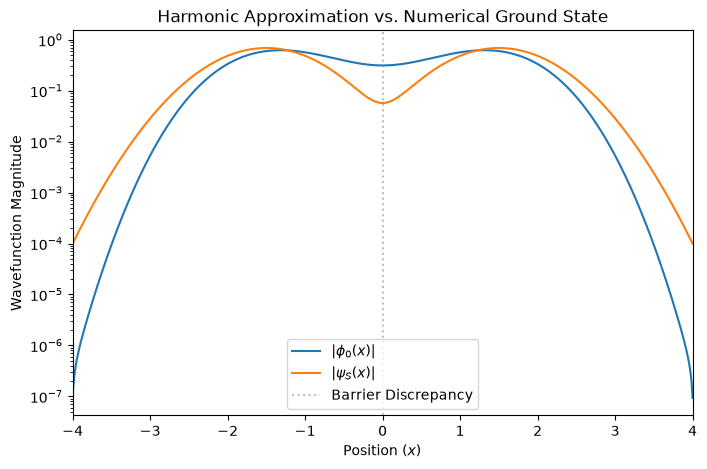

In [32]:
psi_S_norm = psi_S / np.sqrt(
    DX * np.sum(np.abs(psi_S)**2)
)

fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(x, np.abs(phi0), label=r"$|\phi_0(x)|$")
ax.plot(x, np.abs(psi_S_norm), label=r"$|\psi_S(x)|$")

ax.set(
    xlabel="Position $(x)$",
    ylabel="Wavefunction Magnitude",
    title="Harmonic Approximation vs. Numerical Ground State",
    xlim=(-4, 4),
    yscale="log"
)

ax.axvline(0, color="gray", linestyle=":", alpha=0.5,
           label="Barrier Discrepancy")

ax.legend()
plt.show()

### Problem D

In [ ]:
T_D = 2 * np.pi * HBAR / delta_E
NT_D = int(np.ceil(T_D / DT))
t_D = np.arange(NT_D + 1) * DT

x01 = DX * np.sum(phi0 * x * phi1)

x_mean_eig = x01 * np.cos(delta_E * t_D / HBAR)

t_tunnel_eig = np.pi * HBAR / delta_E

print(f"x01 = {x01:.8f}")
print(f"Period T = {T_D:.8f}")
print(f"Two-state tunneling time = {t_tunnel_eig:.8f}")
print(f"Number of time steps = {NT_D}")

x01 = 1.25194209
Period T = 38.58424275
Two-state tunneling time = 19.29212137
Number of time steps = 1573


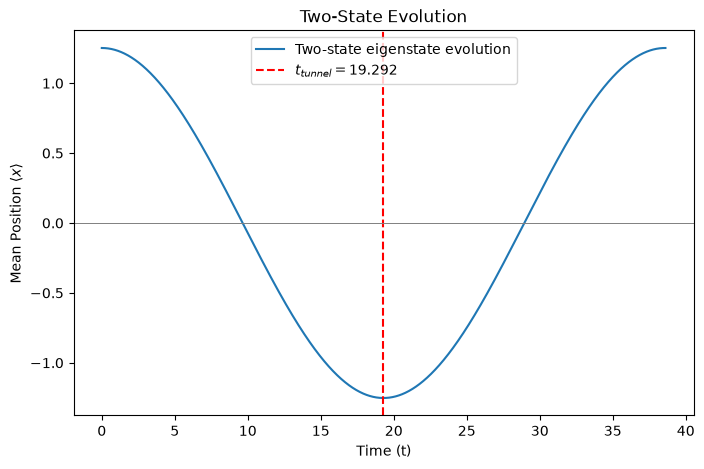

In [17]:
fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(t_D, x_mean_eig, label="Two-state eigenstate evolution")
ax.axvline(t_tunnel_eig, color="red", linestyle="--",
           label=fr"$t_{{tunnel}} = {t_tunnel_eig:.3f}$")
ax.axhline(0, color="gray", linewidth=0.7)

ax.set(
    xlabel="Time (t)",
    ylabel=r"Mean Position $\langle x \rangle$",
    title="Two-State Evolution"
)

ax.legend()
plt.show()

In [18]:
psi_initial_D = ((phi0 + phi1) / np.sqrt(2)).astype(np.complex128)
psi_initial_D /= np.sqrt(DX * np.sum(np.abs(psi_initial_D)**2))

psi_PI_D = evolve(psi_initial_D, K_dt, DX, NT_D)

prob_PI_D = np.abs(psi_PI_D)**2
x_mean_PI_D = DX * (prob_PI_D @ x)

print("Initial norm:", DX * np.sum(np.abs(psi_initial_D)**2))
print("Initial mean position:", x_mean_PI_D[0])

Initial norm: 1.0
Initial mean position: 1.251942087969372


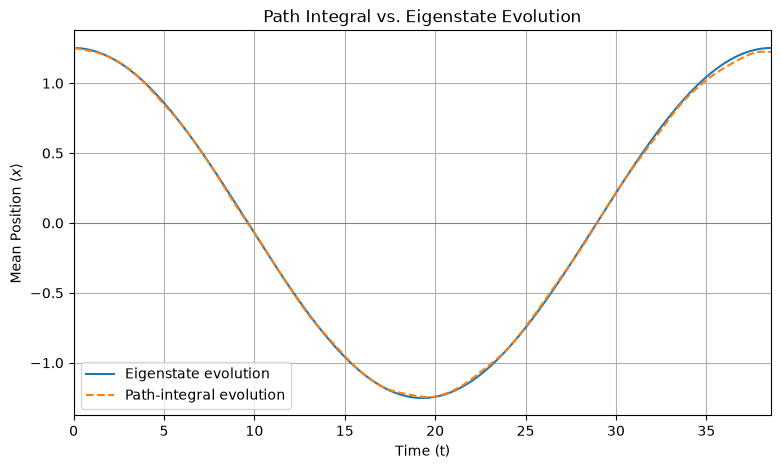

In [19]:
fig, ax = plt.subplots(figsize=(9, 5))

ax.plot(t_D, x_mean_eig, label="Eigenstate evolution")
ax.plot(t_D, x_mean_PI_D, "--", label="Path-integral evolution")

ax.axhline(0, color="gray", linewidth=0.7)

ax.set(
    xlabel="Time (t)",
    ylabel=r"Mean Position $\langle x \rangle$",
    title="Path Integral vs. Eigenstate Evolution",
    xlim=(0, T_D)
)

ax.legend()
ax.grid(True)
plt.show()

In [20]:
valid = t_D <= T_D

differences = np.abs(x_mean_PI_D[valid] - x_mean_eig[valid])

max_index = np.argmax(differences)
max_discrepancy = differences[max_index]

print(f"Maximum discrepancy: {max_discrepancy:.8f}")
print(f"Time: {t_D[max_index]:.8f}")
print(f"PI mean: {x_mean_PI_D[max_index]:.8f}")
print(f"Eigenstate mean: {x_mean_eig[max_index]:.8f}")

Maximum discrepancy: 0.03366176
Time: 36.30012136
PI mean: 1.13267130
Eigenstate mean: 1.16633306


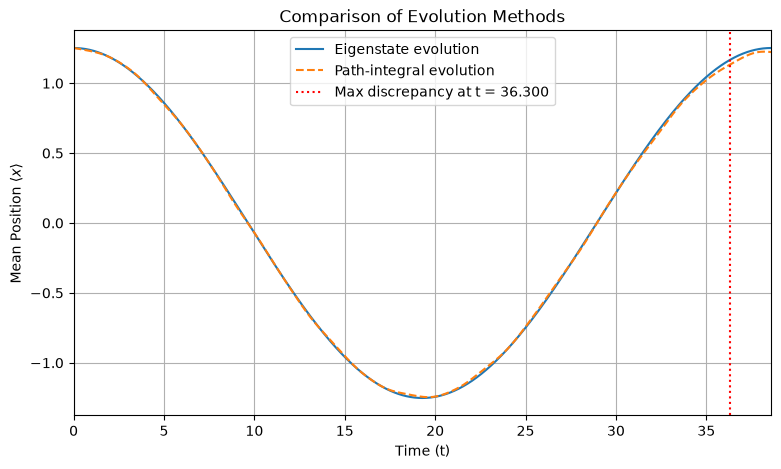

In [21]:
fig, ax = plt.subplots(figsize=(9, 5))

ax.plot(t_D, x_mean_eig, label="Eigenstate evolution")
ax.plot(t_D, x_mean_PI_D, "--", label="Path-integral evolution")

ax.axvline(t_D[max_index], color="red", linestyle=":",
           label=f"Max discrepancy at t = {t_D[max_index]:.3f}")

ax.set(
    xlabel="Time (t)",
    ylabel=r"Mean Position $\langle x \rangle$",
    title="Comparison of Evolution Methods",
    xlim=(0, T_D)
)

ax.legend()
ax.grid(True)
plt.show()

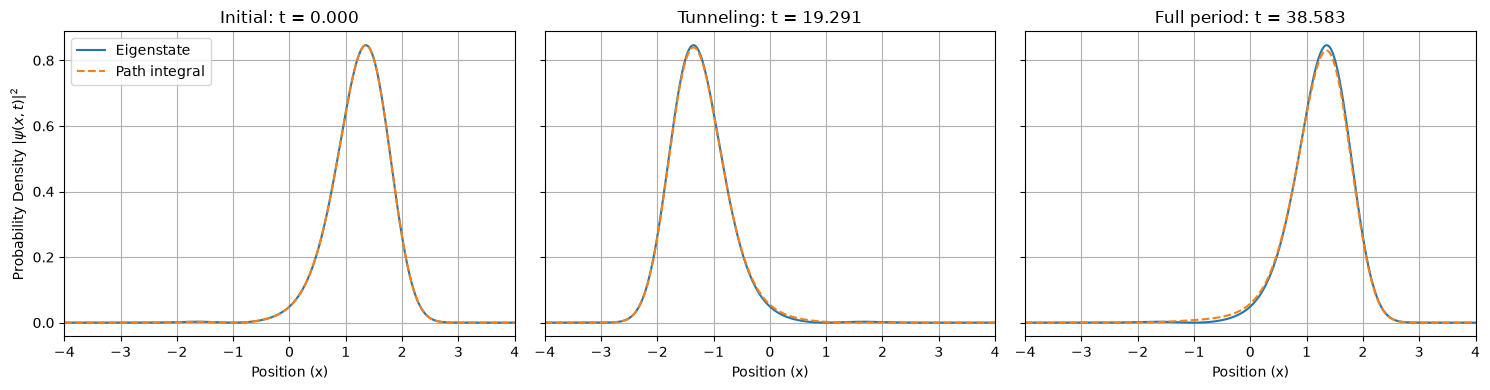

In [22]:
def eigenstate_density(time):
    psi_eig = (
        np.exp(-1j * E0 * time / HBAR) * phi0
        + np.exp(-1j * E1 * time / HBAR) * phi1
    ) / np.sqrt(2)

    return np.abs(psi_eig)**2

snapshot_times = [0, t_tunnel_eig, T_D]
snapshot_labels = ["Initial", "Tunneling", "Full period"]

fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)

for ax, target_time, label in zip(
    axes, snapshot_times, snapshot_labels
):
    n = np.argmin(np.abs(t_D - target_time))
    actual_time = t_D[n]

    prob_eig = eigenstate_density(actual_time)
    prob_pi = prob_PI_D[n]

    ax.plot(x, prob_eig, label="Eigenstate")
    ax.plot(x, prob_pi, "--", label="Path integral")

    ax.set(
        xlabel="Position (x)",
        title=f"{label}: t = {actual_time:.3f}",
        xlim=(-4, 4)
    )
    ax.grid(True)

axes[0].set_ylabel(r"Probability Density $|\psi(x,t)|^2$")
axes[0].legend()

plt.tight_layout()
plt.show()